 # **<font color="DeepPink">Redes Neuronales Convolucionales (CNN)</font>**

  ## **<font color="DeepPink">Pasar de una Red Neuronal Densa a una Red Neuronal Convolucional</font>**




In [ ]:
import tensorflow as tf
import numpy as np

  ## **<font color="DeepPink">El conjunto de datos</font>**

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #202124; padding: 15px; border-left: 5px solid #4285F4; background-color: #f8f9fa; border-radius: 4px;">

  <p>El dataset <strong>Horses or Humans</strong> <em>"ya viene estructurado y normalizado"</em> porque fue diseñado como un ejemplo didáctico dentro de <strong>TensorFlow Datasets (TFDS)</strong>.</p>

  <h3 style="color: #1a73e8; margin-top: 20px; border-bottom: 1px solid #dadce0; padding-bottom: 5px;">¿Qué significa “estructurado”?</h3>
  <ul style="padding-left: 20px;">
    <li><strong>Formato uniforme:</strong> todas las imágenes están en RGB y con la misma forma <code style="background-color: #e8eaed; padding: 2px 5px; border-radius: 3px;">(300, 300, 3)</code>.</li>
    <li><strong>Etiquetas claras:</strong> cada ejemplo es un par <code style="background-color: #e8eaed; padding: 2px 5px; border-radius: 3px;">(imagen, etiqueta)</code> donde la etiqueta es <code style="background-color: #e8eaed; padding: 2px 5px; border-radius: 3px;">0</code> (humano) o <code style="background-color: #e8eaed; padding: 2px 5px; border-radius: 3px;">1</code> (caballo).</li>
    <li><strong>Splits definidos:</strong> ya está dividido en <code style="background-color: #e8eaed; padding: 2px 5px; border-radius: 3px;">train</code> (1.027 imágenes) y <code style="background-color: #e8eaed; padding: 2px 5px; border-radius: 3px;">test</code> (256 imágenes).</li>
  </ul>

  <h3 style="color: #1a73e8; margin-top: 20px; border-bottom: 1px solid #dadce0; padding-bottom: 5px;">¿Qué significa “normalizado”?</h3>
  <ul style="padding-left: 20px;">
    <li><strong>Valores de píxeles:</strong> las imágenes se entregan como tensores <code style="background-color: #e8eaed; padding: 2px 5px; border-radius: 3px;">uint8</code> listos para ser reescalados (ej. con <code style="background-color: #e8eaed; padding: 2px 5px; border-radius: 3px;">Rescaling(1./255)</code>), sin necesidad de convertir manualmente.</li>
    <li><strong>Consistencia:</strong> todas las imágenes tienen el mismo tamaño y formato, lo que evita problemas de entrada en la CNN.</li>
  </ul>

  <div style="margin-top: 15px; padding: 10px 15px; background-color: #e8f0fe; border-radius: 5px; font-size: 0.95em; color: #174ea6;">
    <strong>Comparativa:</strong> En datasets como <em>Cats vs Dogs</em>, las imágenes originales vienen con dimensiones variables y hay que hacer el preprocesamiento (resize, normalización) manualmente.
  </div>

</div>

In [ ]:
!pip install -q importlib_resources

import tensorflow_datasets as tfds

# Cargar el dataset Horses or Humans
dataset, info = tfds.load('horses_or_humans', with_info=True, as_supervised=True)

train_ds = dataset['train']
test_ds = dataset['test']

print("Dataset cargado con éxito.")
print(f"Imágenes de entrenamiento: {info.splits['train'].num_examples}")
print(f"Imágenes de prueba: {info.splits['test'].num_examples}")

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/horses_or_humans/incomplete.1KL57D_3.0.0/horses_or_humans-train.tfrecord-[…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/horses_or_humans/incomplete.1KL57D_3.0.0/horses_or_humans-test.tfrecord-[0…

Dataset horses_or_humans downloaded and prepared to /root/tensorflow_datasets/horses_or_humans/3.0.0. Subsequent calls will reuse this data.
Dataset cargado con éxito.
Imágenes de entrenamiento: 1027
Imágenes de prueba: 256


In [ ]:
train_ds                                                                        # Es la descripción del dataset, no las imágenes en sí.

<_PrefetchDataset element_spec=(TensorSpec(shape=(300, 300, 3), dtype=tf.uint8, name=None), TensorSpec(shape=(), dtype=tf.int64, name=None))>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #202124; padding: 15px; border-left: 5px solid #34A853; background-color: #f8f9fa; border-radius: 4px;">

  <h2 style="color: #1e8e3e; margin-top: 0; border-bottom: 1px solid #dadce0; padding-bottom: 8px;">En el contexto de <code>tf.data.Dataset</code></h2>

  <p>Cuando cargás un dataset con <strong>TensorFlow Datasets</strong> (<code style="background-color: #e8eaed; padding: 2px 5px; border-radius: 3px;">train_ds</code>, <code style="background-color: #e8eaed; padding: 2px 5px; border-radius: 3px;">test_ds</code>), lo que se obtiene es un <strong>iterador de ejemplos</strong>:</p>

  <ul style="padding-left: 20px;">
    <li>Cada vez que lo recorres con un <code style="background-color: #e8eaed; padding: 2px 5px; border-radius: 3px;">for</code>, te devuelve un par <code style="background-color: #e8eaed; padding: 2px 5px; border-radius: 3px;">(imagen, etiqueta)</code>.</li>
    <li>No se puede hacer <code style="background-color: #e8eaed; padding: 2px 5px; border-radius: 3px;">len(train_ds)</code> directamente porque no es una lista, sino un flujo de datos (<em>stream</em>).</li>
    <li>Podés usar métodos como <code style="background-color: #e8eaed; padding: 2px 5px; border-radius: 3px;">.take(n)</code> para obtener los primeros <code style="background-color: #e8eaed; padding: 2px 5px; border-radius: 3px;">n</code> ejemplos.</li>
  </ul>

  <div style="margin-top: 15px; padding: 12px 15px; background-color: #e6f4ea; border-radius: 5px; font-size: 0.95em; color: #137333; border: 1px solid #ceedd5;">
    💡 <strong>Concepto clave:</strong> Un <strong>iterador de ejemplos</strong> es un objeto que te permite recorrer un dataset y obtener sus elementos (imágenes y etiquetas) de manera secuencial, <strong>sin necesidad de tener todo cargado en memoria RAM al mismo tiempo</strong>.
  </div>

</div>

In [ ]:
for image, label in train_ds.take(10):                                          # Me permite iterar sobre los 10 ejemplos del dataset
    print(image.shape, label.numpy())

(300, 300, 3) 0
(300, 300, 3) 0
(300, 300, 3) 0
(300, 300, 3) 0
(300, 300, 3) 0
(300, 300, 3) 0
(300, 300, 3) 0
(300, 300, 3) 1
(300, 300, 3) 1
(300, 300, 3) 1


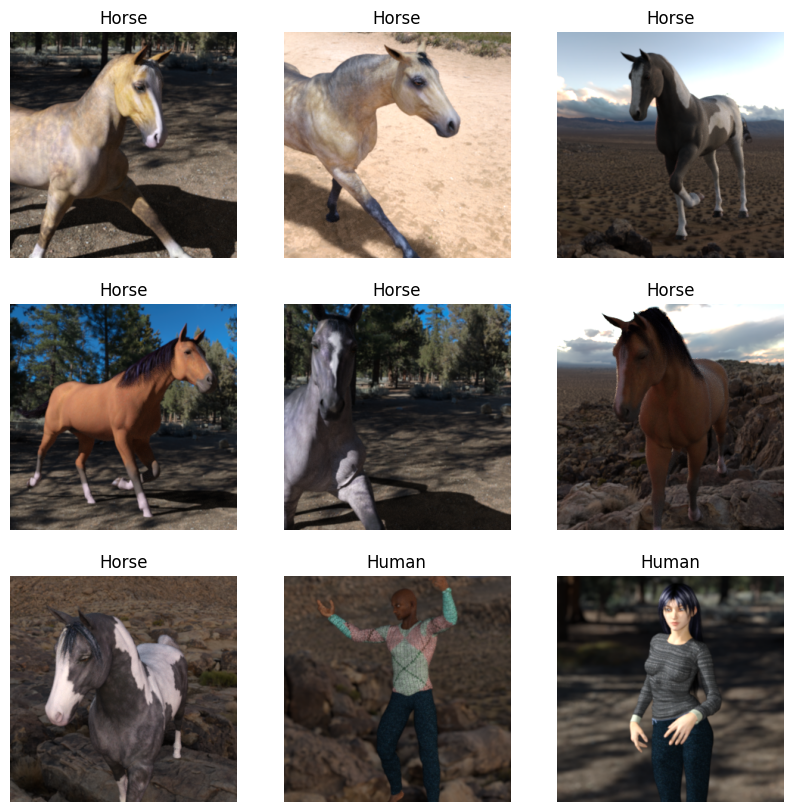

In [ ]:
import matplotlib.pyplot as plt
# Cargar dataset Horses or Humans
# dataset, info = tfds.load('horses_or_humans', with_info=True, as_supervised=True)
# train_ds = dataset['train']

# Diccionario de etiquetas
class_names = {0: "Horse", 1: "Human"}

# Si el dataset está en batches, tomar una sola imagen del batch
for images, labels in train_ds.batch(32).take(1):   # un batch de 32
    plt.figure(figsize=(10, 10))
    for i in range(9):  # mostrar 9 imágenes del batch
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy())   # una sola imagen
        plt.title(class_names[labels[i].numpy()])
        plt.axis("off")
    plt.show()

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #202124; padding: 18px; border-left: 5px solid #FBBC04; background-color: #f8f9fa; border-radius: 6px;">

  <p style="margin-top: 0; margin-bottom: 15px;">
    A continuación, encadenará algunos métodos más para <strong>optimizar los conjuntos de datos</strong> para el entrenamiento y la validación:
  </p>

  <ul style="list-style-type: none; padding-left: 0; margin: 0;">
    <li style="margin-bottom: 12px;">
      <code style="background-color: #fef7e0; color: #b06000; padding: 3px 6px; border-radius: 4px; font-weight: bold; display: inline-block;">cache()</code>
      <span style="display: block; margin-top: 4px; color: #3c4043;">
        Almacena los elementos en la memoria a medida que los usa, por lo que será más rápido recuperarlos si los necesita nuevamente.
      </span>
    </li>
    <li style="margin-bottom: 12px;">
      <code style="background-color: #fef7e0; color: #b06000; padding: 3px 6px; border-radius: 4px; font-weight: bold; display: inline-block;">shuffle()</code>
      <span style="display: block; margin-top: 4px; color: #3c4043;">
        Baraja el conjunto de datos de forma aleatoria. Un <code style="background-color: #e8eaed; padding: 2px 5px; border-radius: 3px;">buffer_size</code> de <code style="background-color: #e8eaed; padding: 2px 5px; border-radius: 3px;">1000</code> significa que primero seleccionará una muestra de los primeros 1.000 elementos y, a continuación, seguirá llenando este búfer hasta que se hayan seleccionado todos los elementos.
      </span>
    </li>
    <li style="margin-bottom: 0;">
      <code style="background-color: #fef7e0; color: #b06000; padding: 3px 6px; border-radius: 4px; font-weight: bold; display: inline-block;">prefetch()</code>
      <span style="display: block; margin-top: 4px; color: #3c4043;">
        Obtiene elementos mientras el modelo se está entrenando, por lo que es más rápido introducir nuevos datos cuando finaliza el paso de entrenamiento actual. Un <code style="background-color: #e8eaed; padding: 2px 5px; border-radius: 3px;">buffer_size</code> establecido en <code style="background-color: #e8eaed; padding: 2px 5px; border-radius: 3px;">tf.data.AUTOTUNE</code> establece dinámicamente el número de elementos que se van a capturar previamente durante el tiempo de ejecución.
      </span>
    </li>
  </ul>

</div>

In [ ]:
# 1. Preprocesamiento: reescalar y preparar batches
rescale = tf.keras.layers.Rescaling(1./255)

train_ds = train_ds.map(lambda img, lbl: (rescale(img), lbl)).shuffle(1000).batch(32).prefetch(tf.data.AUTOTUNE)
test_ds  = test_ds.map(lambda img, lbl: (rescale(img), lbl)).batch(32).prefetch(tf.data.AUTOTUNE)

In [ ]:
info.features.shape

{'image': (300, 300, 3), 'label': ()}

In [ ]:
# Tomamos el primer batch del conjunto de datos de entrenamiento
for images, labels in train_ds.take(1):
    # Extraemos la primera imagen del lote y la convertimos a formato numpy
    first_image_matrix = images[0].numpy()

    print(f"Dimensiones de la matriz de la imagen: {first_image_matrix.shape}")
    print("\nMostrando un fragmento numérico (canal Rojo de una esquina de 5x5 píxeles):\n")
    # Mostramos los valores numéricos de una sección de 5x5 píxeles para el primer canal de color (Rojo)
    print(first_image_matrix[:5, :5, 0])

    print("\nRepresentación matricial completa del tensor:")
    print(first_image_matrix)

Dimensiones de la matriz de la imagen: (300, 300, 3)

Mostrando un fragmento numérico (canal Rojo de una esquina de 5x5 píxeles):

[[0.37647063 0.42352945 0.427451   0.40000004 0.37647063]
 [0.39607847 0.43137258 0.42352945 0.36862746 0.30980393]
 [0.42352945 0.4039216  0.38431376 0.3529412  0.26666668]
 [0.427451   0.40000004 0.38431376 0.3529412  0.2901961 ]
 [0.3921569  0.3529412  0.3529412  0.3137255  0.3019608 ]]

Representación matricial completa del tensor:
[[[0.37647063 0.37647063 0.2901961 ]
  [0.42352945 0.41960788 0.33333334]
  [0.427451   0.427451   0.34901962]
  ...
  [0.08235294 0.08235294 0.06666667]
  [0.1137255  0.11764707 0.09019608]
  [0.1254902  0.12941177 0.10196079]]

 [[0.39607847 0.38823533 0.29411766]
  [0.43137258 0.427451   0.3372549 ]
  [0.42352945 0.42352945 0.34509805]
  ...
  [0.14509805 0.15294118 0.1137255 ]
  [0.16078432 0.17254902 0.1254902 ]
  [0.14509805 0.15294118 0.11764707]]

 [[0.42352945 0.4039216  0.30588236]
  [0.4039216  0.40000004 0.3019608

 ## **<font color="DeepPink">DNN</font>**

In [ ]:
model = tf.keras.Sequential([

    # 1. Capa Flatten (Aplanado):
    # Convierte la matriz 3D de la imagen (ej. 300x300x3) en un único vector 1D de 270.000 valores.
    # Usa 'info.features['image'].shape' para obtener automáticamente la forma de entrada desde TFDS.
    tf.keras.layers.Flatten(input_shape=info.features['image'].shape),

    # 2. Primera Capa Densa (Oculta):
    # Capa totalmente conectada con 128 neuronas.
    # 'relu' (Rectified Linear Unit) introduce no-linealidad para aprender patrones complejos.
    tf.keras.layers.Dense(128, activation='relu'),

    # 3. Primer Dropout (Regularización):
    # Desactiva aleatoriamente el 30% de las neuronas en cada paso de entrenamiento
    # para reducir el sobreajuste (overfitting).
    tf.keras.layers.Dropout(0.3),

    # 4. Segunda Capa Densa (Oculta):
    # Reduce la dimensionalidad a 64 neuronas para consolidar la información aprendida.
    tf.keras.layers.Dense(64, activation='relu'),

    # 5. Segundo Dropout (Regularización):
    # Vuelve a apagar el 30% de las neuronas para mantener la robustez del modelo.
    tf.keras.layers.Dropout(0.3),

    # 6. Capa de Salida Densa:
    # Una sola neurona con activación 'sigmoid', que produce una probabilidad continua entre 0 y 1.
    # Ideal para clasificación binaria (0 = Humano, 1 = Caballo).
    tf.keras.layers.Dense(1, activation='sigmoid')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 270000)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    34,560,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,568,449 (131.87 MB)

 Trainable params: 34,568,449 (131.87 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
 # 3. Compilar
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [ ]:
# 4. Entrenar
history = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=10,
    verbose=2
)

Epoch 1/10
33/33 - 8s - 248ms/step - accuracy: 0.5239 - loss: 28.7719 - val_accuracy: 0.6719 - val_loss: 3.5110
Epoch 2/10
33/33 - 2s - 51ms/step - accuracy: 0.5287 - loss: 1.4741 - val_accuracy: 0.5000 - val_loss: 0.6932
Epoch 3/10
33/33 - 2s - 72ms/step - accuracy: 0.4869 - loss: 0.6934 - val_accuracy: 0.5000 - val_loss: 0.6932
Epoch 4/10
33/33 - 2s - 48ms/step - accuracy: 0.4869 - loss: 0.6934 - val_accuracy: 0.5000 - val_loss: 0.6932
Epoch 5/10
33/33 - 2s - 47ms/step - accuracy: 0.4869 - loss: 0.6933 - val_accuracy: 0.5000 - val_loss: 0.6932
Epoch 6/10
33/33 - 3s - 85ms/step - accuracy: 0.4869 - loss: 0.6932 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 7/10
33/33 - 2s - 71ms/step - accuracy: 0.4995 - loss: 0.6932 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 8/10
33/33 - 3s - 76ms/step - accuracy: 0.5131 - loss: 0.6931 - val_accuracy: 0.5000 - val_loss: 0.6932
Epoch 9/10
33/33 - 2s - 47ms/step - accuracy: 0.5131 - loss: 0.6931 - val_accuracy: 0.5000 - val_loss: 0.6932
Epoch 10

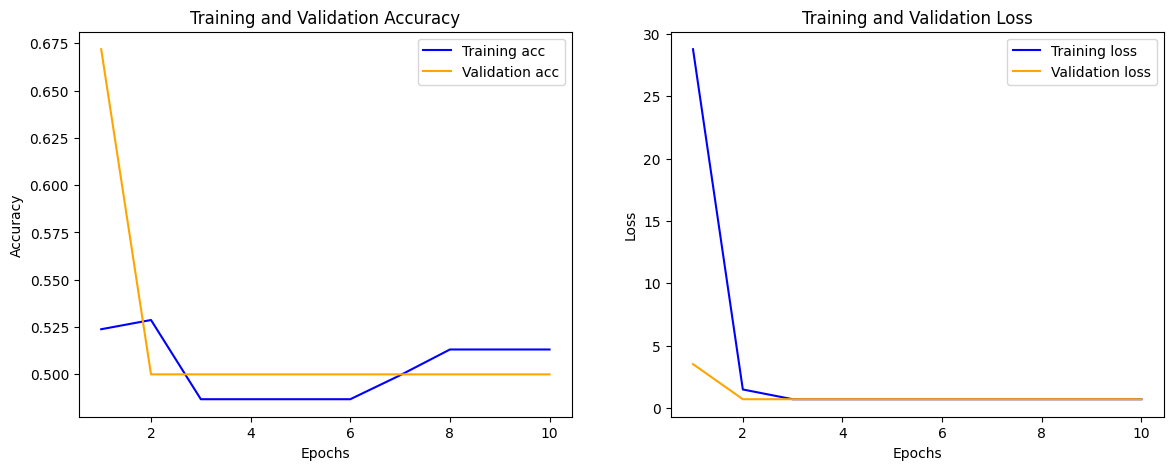

In [ ]:
import matplotlib.pyplot as plt

def plot_acc_loss(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs = range(1, len(acc) + 1)

    fig, ax = plt.subplots(1, 2, figsize=(14, 5))

    # Accuracy
    ax[0].plot(epochs, acc, label='Training acc', color='blue')
    ax[0].plot(epochs, val_acc, label='Validation acc', color='orange')
    ax[0].set_title('Training and Validation Accuracy')
    ax[0].set_xlabel('Epochs')
    ax[0].set_ylabel('Accuracy')
    ax[0].legend()

    # Loss
    ax[1].plot(epochs, loss, label='Training loss', color='blue')
    ax[1].plot(epochs, val_loss, label='Validation loss', color='orange')
    ax[1].set_title('Training and Validation Loss')
    ax[1].set_xlabel('Epochs')
    ax[1].set_ylabel('Loss')
    ax[1].legend()

    plt.show()

# Llamada
plot_acc_loss(history)


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #202124; padding: 18px; border-left: 5px solid #EA4335; background-color: #f8f9fa; border-radius: 6px;">

  <h2 style="color: #c5221f; margin-top: 0; border-bottom: 1px solid #dadce0; padding-bottom: 8px;">Conclusión</h2>
  <p style="margin-top: 10px;">
    El uso del dataset <strong>Horses or Humans</strong> con una red neuronal densa (<strong>DNN</strong>) no resulta adecuado para demostrar un buen desempeño en clasificación de imágenes. La razón principal es el tamaño limitado del conjunto de datos (alrededor de 1.000 imágenes de entrenamiento y 250 de validación), lo que provoca que el modelo se quede rápidamente en predicciones cercanas al azar.
  </p>
  <ul style="list-style-type: none; padding-left: 0; margin: 15px 0;">
    <li style="margin-bottom: 12px;">
      <strong style="color: #c5221f;">Pérdida de información espacial:</strong>
      <span style="display: block; margin-top: 3px; color: #3c4043;">
        Una DNN aplana las imágenes en vectores muy grandes, perdiendo la estructura espacial que contiene información clave sobre bordes, formas y texturas.
      </span>
    </li>
    <li style="margin-bottom: 0;">
      <strong style="color: #c5221f;">Falta de generalización:</strong>
      <span style="display: block; margin-top: 3px; color: #3c4043;">
        El modelo no logra aprender patrones visuales relevantes y su <em>accuracy</em> en validación se mantiene en torno a <code style="background-color: #fce8e6; color: #c5221f; padding: 2px 6px; border-radius: 3px; font-weight: bold;">0.50</code>, reflejando que no generaliza.
      </span>
    </li>
  </ul>
  <div style="margin-top: 15px; padding: 12px 15px; background-color: #fce8e6; border-radius: 5px; font-size: 0.95em; color: #a50e0e; border: 1px solid #f5c2c7;">
    📌 <strong>Valor pedagógico:</strong> Este resultado permite evidenciar las limitaciones de las DNN en visión por computadora. La comparación posterior con una <strong>CNN</strong> demuestra cómo aprovechar la estructura espacial de las imágenes mejora los resultados, aunque deja claro que la cantidad de datos impone un límite al rendimiento alcanzable.
  </div>

</div>

 ## **<font color="DeepPink">CNN</font>**

A diferencia de las Redes Neuronales Densas (DNN) que aplanan las imágenes perdiendo la relación de vecindad entre píxeles, las **CNN (Convolutional Neural Networks)** están diseñadas específicamente para procesar datos con estructura de cuadrícula, como las imágenes, preservando la información espacial.

#### **Componentes Clave de una CNN:**

1. **Capa de Convolución (Conv2D):**
   * Utiliza filtros o "kernels" (pequeñas matrices de pesos como de $3 \times 3$) que se deslizan a lo largo de la imagen.
   * Realiza un producto punto para generar un **mapa de características** (*feature map*), que resalta patrones visuales como bordes, texturas o formas.
   
2. **Función de Activación (ReLU):**
   * Se aplica después de la convolución para introducir no linealidad en el modelo, permitiendo aprender patrones complejos complejos.

3. **Capa de Reducción / Agrupación (MaxPooling2D):**
   * Reduce las dimensiones espaciales (ancho y alto) de los mapas de características.
   * Al quedarse con el valor máximo de cada región (ej. de $2 \times 2$), reduce el costo computacional, previene el sobreajuste y otorga cierta **invarianza a la traslación** (detecta el patrón sin importar su posición exacta).

4. **Capa de Aplanado (Flatten) y Capas Densas (Dense):**
   * Al final de las etapas convolucionales, los mapas de características tridimensionales se aplanan en un vector unidimensional.
   * Este vector se conecta a capas densas tradicionales para realizar la clasificación final basada en las características abstractas extraídas.

In [ ]:
# Definición del modelo secuencial de Red Neuronal Convolucional (CNN)
model_cnn = tf.keras.Sequential([

    # 1. Capa de entrada: Define la forma de las imágenes (300x300 píxeles, 3 canales RGB)
    tf.keras.Input(shape=(300, 300, 3)),

    # 2. Primera Convolución: 8 filtros de 3x3 para detectar bordes y patrones simples + ReLU
    tf.keras.layers.Conv2D(8, (3, 3), activation='relu'),

    # 3. Primer Pooling: Reduce el tamaño espacial a la mitad conservando el valor máximo
    tf.keras.layers.MaxPooling2D(2, 2),

    # 4. Primer Dropout: Desactiva aleatoriamente el 30% de las neuronas para evitar overfitting
    tf.keras.layers.Dropout(0.3),

    # 5. Segunda Convolución: 16 filtros de 3x3 para extraer patrones más complejos + ReLU
    tf.keras.layers.Conv2D(16, (3, 3), activation='relu'),

    # 6. Segundo Pooling: Reduce nuevamente el tamaño espacial a la mitad
    tf.keras.layers.MaxPooling2D(2, 2),

    # 7. Segundo Dropout: Desactiva el 30% de las neuronas para regularización
    tf.keras.layers.Dropout(0.3),

    # 8. Tercera Convolución: 32 filtros de 3x3 para capturar características detalladas + ReLU
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),

    # 9. Tercer Pooling: Última reducción espacial antes de la clasificación
    tf.keras.layers.MaxPooling2D(2, 2),

    # 10. Tercer Dropout: Mantiene la reducción de overfitting
    tf.keras.layers.Dropout(0.3),

    # 11. Flatten: Aplana los mapas de características 3D en un vector 1D
    tf.keras.layers.Flatten(),

    # 12. Capa Densa: 32 neuronas totalmente conectadas para combinar las características
    tf.keras.layers.Dense(32, activation='relu'),

    # 13. Dropout FinaI: Desactiva el 50% de las conexiones de la capa densa
    tf.keras.layers.Dropout(0.5),

    # 14. Capa de Salida: 1 neurona con Sigmoid para probabilidad entre 0 y 1 (Humano / Caballo)
    tf.keras.layers.Dense(1, activation='sigmoid')
])

# Mostrar el resumen de arquitecturas, formas de salida y parámetros entrenables
model_cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 298, 298, 8)    │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 149, 149, 8)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 149, 149, 8)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 147, 147, 16)   │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 73, 73, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 73, 73, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 71, 71, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 35, 35, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 35, 35, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 39200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │     1,254,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,260,497 (4.81 MB)

 Trainable params: 1,260,497 (4.81 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model_cnn.compile(loss='binary_crossentropy',
              optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
              metrics=['accuracy'])

In [ ]:
history = model_cnn.fit(
    train_ds,
    epochs=10,
    validation_data=test_ds,
    verbose=2
)

Epoch 1/10
33/33 - 21s - 645ms/step - accuracy: 0.4839 - loss: 0.7145 - val_accuracy: 0.5000 - val_loss: 0.6942
Epoch 2/10
33/33 - 2s - 65ms/step - accuracy: 0.5122 - loss: 0.6850 - val_accuracy: 0.5000 - val_loss: 0.6926
Epoch 3/10
33/33 - 2s - 75ms/step - accuracy: 0.5443 - loss: 0.6834 - val_accuracy: 0.5078 - val_loss: 0.6909
Epoch 4/10
33/33 - 3s - 77ms/step - accuracy: 0.5686 - loss: 0.6701 - val_accuracy: 0.5000 - val_loss: 0.6913
Epoch 5/10
33/33 - 2s - 62ms/step - accuracy: 0.5735 - loss: 0.6625 - val_accuracy: 0.5000 - val_loss: 0.6853
Epoch 6/10
33/33 - 3s - 84ms/step - accuracy: 0.6203 - loss: 0.6430 - val_accuracy: 0.5156 - val_loss: 0.6756
Epoch 7/10
33/33 - 2s - 63ms/step - accuracy: 0.6417 - loss: 0.6141 - val_accuracy: 0.8555 - val_loss: 0.6350
Epoch 8/10
33/33 - 2s - 62ms/step - accuracy: 0.6748 - loss: 0.5828 - val_accuracy: 0.6992 - val_loss: 0.6190
Epoch 9/10
33/33 - 2s - 62ms/step - accuracy: 0.6913 - loss: 0.5559 - val_accuracy: 0.5703 - val_loss: 0.6227
Epoch 10

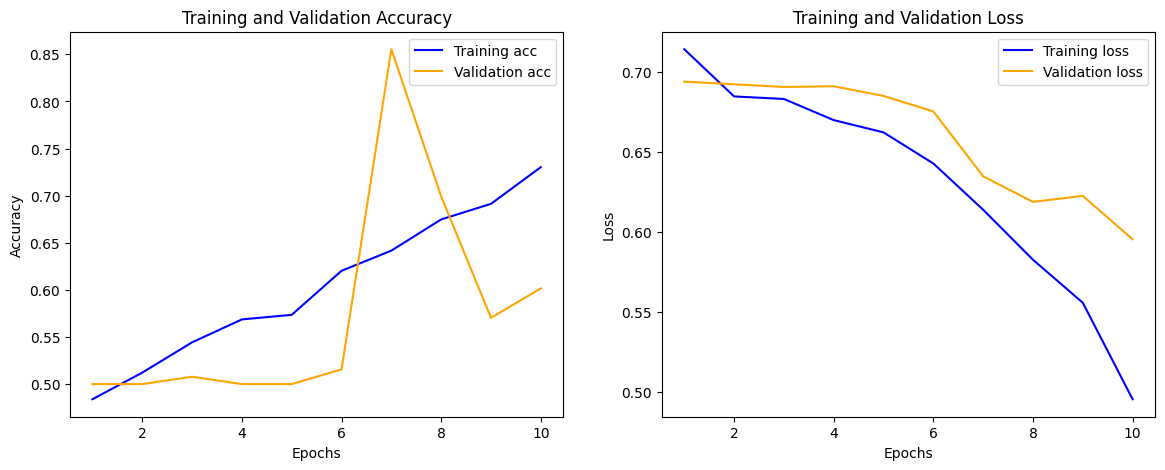

In [ ]:
import matplotlib.pyplot as plt

def plot_acc_loss(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs = range(1, len(acc) + 1)

    fig, ax = plt.subplots(1, 2, figsize=(14, 5))

    # Accuracy
    ax[0].plot(epochs, acc, label='Training acc', color='blue')
    ax[0].plot(epochs, val_acc, label='Validation acc', color='orange')
    ax[0].set_title('Training and Validation Accuracy')
    ax[0].set_xlabel('Epochs')
    ax[0].set_ylabel('Accuracy')
    ax[0].legend()

    # Loss
    ax[1].plot(epochs, loss, label='Training loss', color='blue')
    ax[1].plot(epochs, val_loss, label='Validation loss', color='orange')
    ax[1].set_title('Training and Validation Loss')
    ax[1].set_xlabel('Epochs')
    ax[1].set_ylabel('Loss')
    ax[1].legend()

    plt.show()

# Llamada
plot_acc_loss(history)


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #202124; padding: 18px; border-left: 5px solid #EA4335; background-color: #f8f9fa; border-radius: 6px;">

  <h2 style="color: #c5221f; margin-top: 0; border-bottom: 1px solid #dadce0; padding-bottom: 8px;">Conclusión</h2>
  <p style="margin-top: 10px;">
    la CNN mejora respecto a la DNN, pero en este ejemplo sigue siendo insuficiente porque el dataset es demasiado pequeño para sostener una generalización adecuada.